# Paper 24: Hard FCF floor

v2 keeps the **top half of Halal S&P 500 names by FCF / sales**. That is a rank cutoff, not a quality hurdle. In the old diagnostics the median sat around **4%**. On fully invested days that book still lagged SPUS. This paper asks whether a **yes/no cash-conversion line** stops the loose tail that makes v2 a slower SPUS clone.

Replace `keep_quantile=0.5` with a fixed FCF-margin floor. Do **not** restack conversion / stability / yield — that is paper 19. If the floor leaves fewer than 20 names, **do not relax it**. Own the names that clear the line; leave the rest of NAV in cash (cash still yields 0% until paper 21).

Change only `signal`. Overlay, construction, execution, and screens stay on v2. Scored against **v2 baseline**. Kill rules are frozen in `Research/book-construction-status.md`:

- Train 2022 calendar more than 5pp worse than SPUS
- Train max drawdown worse than SPUS
- Train Calmar below both v2 baseline and SPUS
- Test 2023 calendar more than 15pp worse than v2 baseline

**Variants.** floor-6, floor-8, floor-10. Kill a floor if the book goes empty in 2022, or if Calmar does not move — then the lag was never the tail.


In [10]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "monterey" / "__init__.py").exists():
            return candidate
    raise FileNotFoundError(f"Monterey repo root not found from {start}")

_ROOT = _repo_root()
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))
try:
    import monterey  # noqa: F401
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-e", f"{_ROOT}[research]"])

from monterey.research import boot, compare, run_book
from monterey.sprints import score_against_baseline
from monterey.spec import BookSpec

rd = boot("paper-24-hard-fcf-margins", start="2019-12-01", end="2026-09-30")
print("snapshot", rd.manifest.get("hash"))
print("v2 hash", BookSpec.load("fcf-sma-v2-baseline").hash())

base = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="24-hard-fcf-margins",
    id="v2",
)


[monterey.data] Loading snapshot ebbbefb35545
        field                   value
       window 2019-12-01 → 2026-09-30
     universe    sp500, point-in-time
      symbols                     631
    snapshots                      85
   price rows                 1147266
    dividends                    9754
filing events                   61274
   halalquant                   0.4.0
snapshot hash            ebbbefb35545
snapshot ebbbefb35545
v2 hash 6ca86844209e


## One floor at a time

Each trial copies v2 and sets only `signal.params.margin_floor`. `keep_quantile` is still on the spec (merge), but the brain ignores it when the floor is set and does not fill back to 20 names.


In [11]:
floor_6 = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="24-hard-fcf-margins",
    id="floor-6",
    signal={"params": {"margin_floor": 0.06}},
)
floor_8 = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="24-hard-fcf-margins",
    id="floor-8",
    signal={"params": {"margin_floor": 0.08}},
)
floor_10 = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="24-hard-fcf-margins",
    id="floor-10",
    signal={"params": {"margin_floor": 0.10}},
)

trials = [floor_6, floor_8, floor_10]
for book in [base, *trials]:
    print(book.spec.id, book.spec.hash())
    print(" ", dict(book.spec.summary()))
    assert book.spec.hash() != base.spec.hash() or book is base


v2 6ca86844209e
  {'book': 'v2', 'hash': '6ca86844209e', 'universe': 'sp500 point-in-time', 'sector screen': 'on', 'AAOIFI lines': 'debt 30% / cash 30% / recv 70%', 'breach exit': 'next_open', 'brain': 'fcf_quality (keep_quantile=0.5, min_holdings=20)', 'weights': 'cap', 'name cap': '10%', 'sector cap': 'none', 'sector floors': 'none', 'throttle': 'SPY 200-day SMA', 'rebalance': 'daily_to_target, drift band 0.0%, min $100', 'dividends': 'credited', 'cost': '10 bp charged', 'purify': 'ex_date'}
floor-6 d39dffea6790
  {'book': 'floor-6', 'hash': 'd39dffea6790', 'universe': 'sp500 point-in-time', 'sector screen': 'on', 'AAOIFI lines': 'debt 30% / cash 30% / recv 70%', 'breach exit': 'next_open', 'brain': 'fcf_quality (keep_quantile=0.5, margin_floor=0.06, min_holdings=20)', 'weights': 'cap', 'name cap': '10%', 'sector cap': 'none', 'sector floors': 'none', 'throttle': 'SPY 200-day SMA', 'rebalance': 'daily_to_target, drift band 0.0%, min $100', 'dividends': 'credited', 'cost': '10 bp char

In [12]:
compare([base, *trials], rd)


,total_return,cagr,volatility,max_drawdown,calmar,sharpe,sortino,turnover,costs_pct,dividends_pct,avg_exposure,switches,hash
book,,,,,,,,,,,,,
v2,1.0644,0.1137,0.1463,-0.2482,0.4582,0.6752,0.8589,4.1653,0.0561,0.0561,0.8032,36.0000,6ca86844209e
floor-6,0.8052,0.0917,0.1492,-0.2469,0.3716,0.5308,0.6686,4.4172,0.0595,0.0598,0.8032,36.0000,d39dffea6790
floor-8,0.8191,0.0930,0.1503,-0.2390,0.3890,0.5356,0.6851,4.6780,0.0630,0.0586,0.8032,36.0000,a42931d2a66b
floor-10,0.9471,0.1041,0.1437,-0.2427,0.4288,0.6239,0.7979,4.8635,0.0655,0.0640,0.8032,36.0000,87ee19f1cdaa
SPUS (total return),2.1167,0.1840,0.2116,-0.3080,0.5975,0.8123,1.0828,NaN,NaN,NaN,NaN,NaN,NaN
SPY (total return),1.6113,0.1533,0.2006,-0.3372,0.4547,0.7140,0.8854,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
for trial in trials:
    verdict = score_against_baseline(trial, base, rd)
    reasons = "; ".join(verdict["reasons"]) or "pass"
    print(trial.spec.id, "KILLED" if verdict["killed"] else "keep", reasons)


floor-6 KILLED train Calmar below both v2 baseline and SPUS
floor-8 KILLED train Calmar below both v2 baseline and SPUS
floor-10 KILLED train Calmar below both v2 baseline and SPUS


## Did the floor bind?

`compare` only sees NAV. Before we trust a Calmar move, check that the floor actually raised the worst FCF margin, cut names versus the median rule, and left cash when the list was short — rather than filling back with 4% converters.


In [14]:
import pandas as pd
from monterey.layers import screen
from monterey.layers.signals import Context, run_brain

DAYS = ["2020-03-31", "2022-06-30", "2023-12-29", "2024-12-31"]

SPECS = {
    "v2": BookSpec.load("fcf-sma-v2-baseline"),
    "floor-6": BookSpec.load("fcf-sma-v2-baseline").replace(
        id="floor-6", signal={"params": {"margin_floor": 0.06}}
    ),
    "floor-8": BookSpec.load("fcf-sma-v2-baseline").replace(
        id="floor-8", signal={"params": {"margin_floor": 0.08}}
    ),
    "floor-10": BookSpec.load("fcf-sma-v2-baseline").replace(
        id="floor-10", signal={"params": {"margin_floor": 0.10}}
    ),
}


def pick(spec, day: str) -> pd.DataFrame:
    held = screen(rd, day, spec)
    return run_brain(Context(data=rd, spec=spec, as_of=pd.Timestamp(day).date(), screen=held))


rows = []
for day in DAYS:
    base_names = set(pick(SPECS["v2"], day)["symbol"].astype(str))
    for name, spec in SPECS.items():
        picked = pick(spec, day)
        names = set(picked["symbol"].astype(str)) if not picked.empty else set()
        scores = pd.to_numeric(picked["score"], errors="coerce") if not picked.empty else pd.Series(dtype=float)
        rows.append(
            {
                "day": day,
                "book": name,
                "n": len(names),
                "dropped_vs_v2": len(base_names - names),
                "added_vs_v2": len(names - base_names),
                "min_fcf_margin": float(scores.min()) if len(scores) else None,
                "median_fcf_margin": float(scores.median()) if len(scores) else None,
                "short_of_20": len(names) < 20,
            }
        )

census = pd.DataFrame(rows)
census


,day,book,n,dropped_vs_v2,added_vs_v2,min_fcf_margin,median_fcf_margin,short_of_20
0,2020-03-31,v2,83,0,0,0.0326,0.0677,False
1,2020-03-31,floor-6,44,39,0,0.0630,0.1156,False
2,2020-03-31,floor-8,36,47,0,0.0802,0.1318,False
3,2020-03-31,floor-10,26,57,0,0.1056,0.1448,False
4,2022-06-30,v2,99,0,0,0.0663,0.1110,False
5,2022-06-30,floor-6,107,0,8,0.0604,0.1038,False
6,2022-06-30,floor-8,80,19,0,0.0803,0.1252,False
7,2022-06-30,floor-10,61,38,0,0.1004,0.1521,False
8,2023-12-29,v2,96,0,0,0.0327,0.0720,False
9,2023-12-29,floor-6,57,39,0,0.0600,0.1190,False


## Path, not just the scorecard

Plot growth of $1 and drawdown. Then the quantity the rule claims to change: how many names the floor keeps, and how much NAV sits in cash when the list is short.


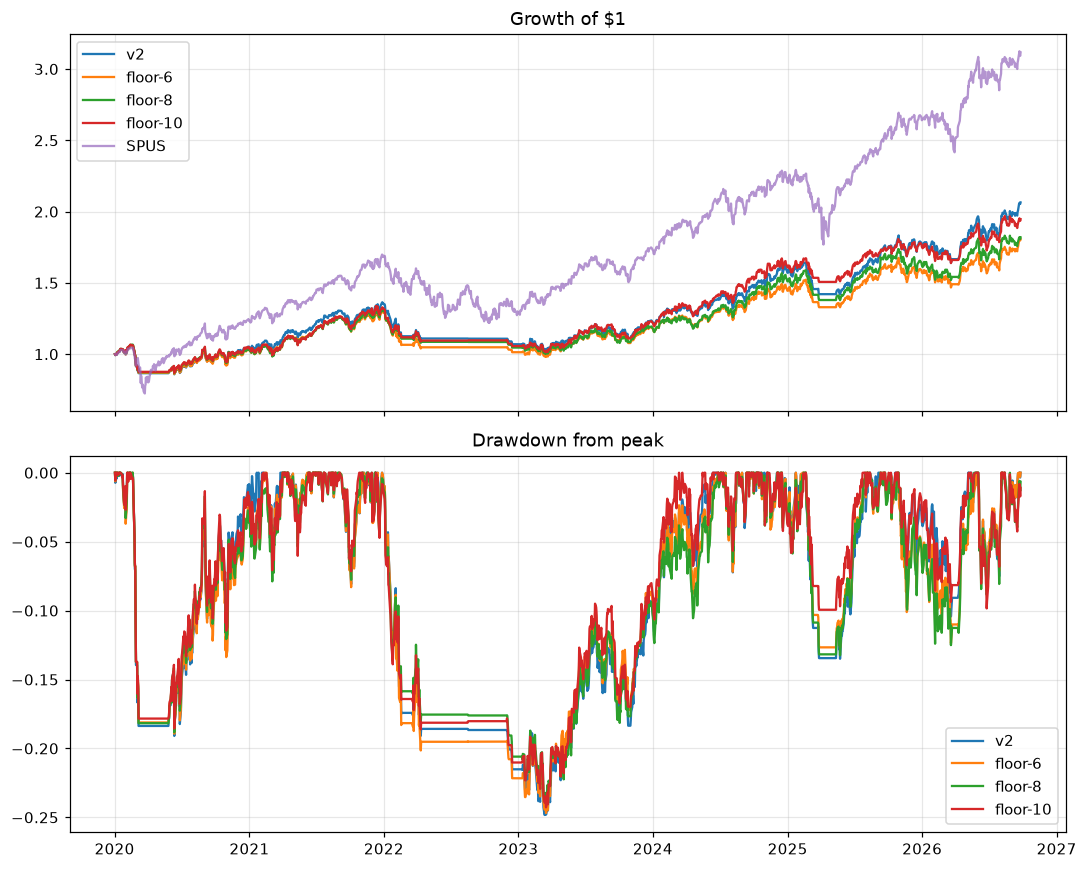

wrote figures/nav-and-drawdown.png


In [15]:
import matplotlib.pyplot as plt
from monterey.diagnostics import yearly

books = [base, *trials]
figures = Path("figures")
figures.mkdir(exist_ok=True)

spus = rd.total_return("SPUS").reindex(base.nav_series().index).ffill()

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
for book in books:
    nav = book.nav_series()
    axes[0].plot(nav.index, nav / nav.iloc[0], label=book.spec.id)
    dd = nav / nav.cummax() - 1.0
    axes[1].plot(dd.index, dd, label=book.spec.id)
axes[0].plot(spus.index, spus / spus.iloc[0], label="SPUS", alpha=0.7)
axes[0].set_title("Growth of $1")
axes[0].legend()
axes[1].set_title("Drawdown from peak")
axes[1].legend()
fig.tight_layout()
fig.savefig(figures / "nav-and-drawdown.png", dpi=140)
plt.show()
print("wrote", figures / "nav-and-drawdown.png")


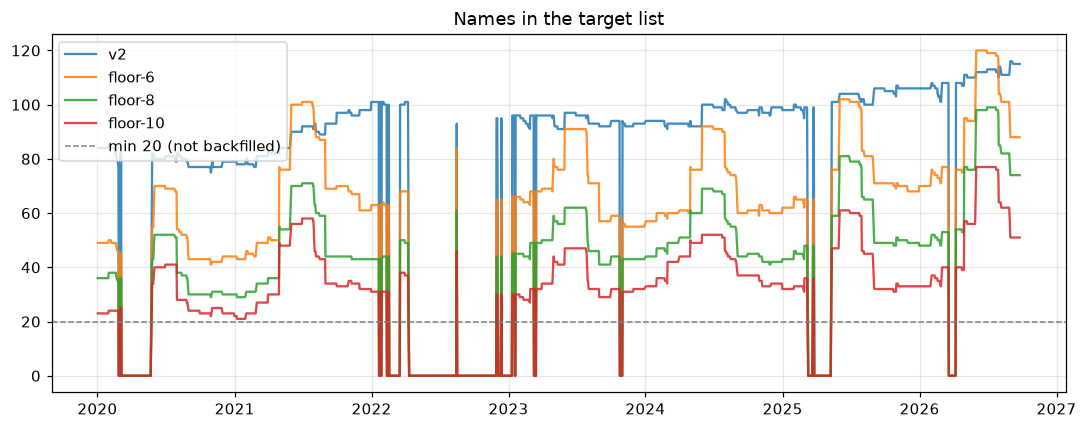

wrote figures/name-count.png


In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
for book in books:
    ax.plot(book.nav["date"], book.nav["n_targets"], label=book.spec.id, alpha=0.85)
ax.axhline(20, color="0.5", linestyle="--", linewidth=1, label="min 20 (not backfilled)")
ax.set_title("Names in the target list")
ax.legend()
fig.tight_layout()
fig.savefig(figures / "name-count.png", dpi=140)
plt.show()
print("wrote", figures / "name-count.png")


,v2,floor-6,floor-8,floor-10,SPUS
year,,,,,
2020,0.0528,0.0352,0.0360,0.0484,0.2399
2021,0.2831,0.2457,0.2566,0.2579,0.3562
2022,-0.2080,-0.2140,-0.1963,-0.1987,-0.2276
2023,0.1525,0.1716,0.1387,0.1618,0.3420
2024,0.2741,0.2167,0.2682,0.3110,0.2649
2025,0.1250,0.0897,0.0755,0.0899,0.1978
2026,0.1681,0.1465,0.1194,0.1100,0.1802


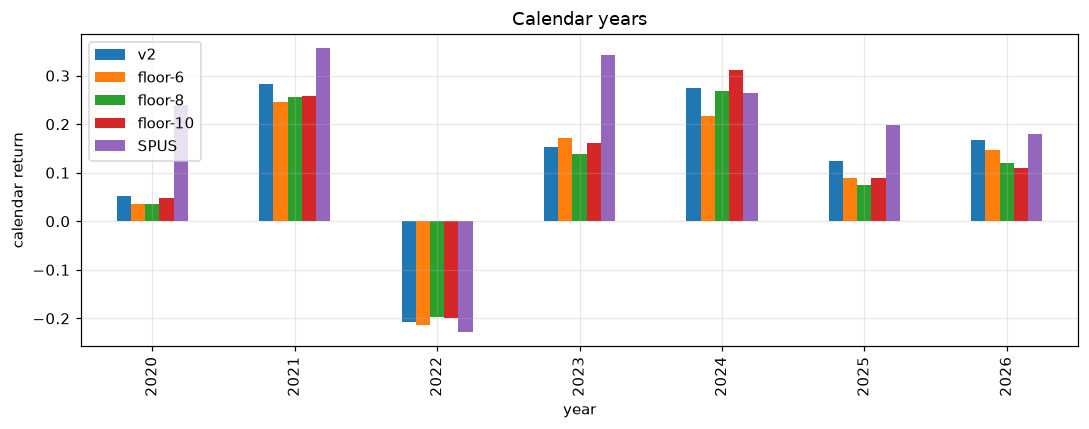

wrote figures/calendar-returns.png


In [17]:
calendar = pd.concat({book.spec.id: yearly(book.nav_series())["return"] for book in books}, axis=1)
calendar["SPUS"] = yearly(spus)["return"]
display(calendar)

ax = calendar.plot(kind="bar", figsize=(10, 4))
ax.set_ylabel("calendar return")
ax.set_title("Calendar years")
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(figures / "calendar-returns.png", dpi=140)
plt.show()
print("wrote", figures / "calendar-returns.png")


## Cash when the list is short

The overlay already parks NAV in cash when SPY is below its 200-day. This cell isolates days the **switch is on** but the floor still left equity unfilled — the paper-24 mechanism, not the SMA.


In [18]:
from monterey.diagnostics import diagnose

rows = []
for book in books:
    nav = book.nav.copy()
    nav["date"] = pd.to_datetime(nav["date"])
    invested_frac = nav["invested"] / nav["nav"]
    on = nav["regime_on"].astype(bool)
    empty_on = on & (nav["n_targets"] == 0)
    short_on = on & (nav["n_targets"] < 20)
    cash_on = on & (invested_frac < 0.95)
    diag = diagnose(book, rd)
    rows.append(
        {
            "book": book.spec.id,
            "avg_n_targets": float(nav["n_targets"].mean()),
            "min_n_targets": int(nav["n_targets"].min()),
            "sessions_empty_while_on": int(empty_on.sum()),
            "sessions_under_20_while_on": int(short_on.sum()),
            "sessions_under_95pct_invested_while_on": int(cash_on.sum()),
            "mean_invested_frac_while_on": float(invested_frac[on].mean()) if on.any() else None,
        }
    )
    print(book.spec.id, "IT last session", diag.get("sectors"))

pd.DataFrame(rows)


v2 IT last session {'information technology': 0.6556860463020436, 'communication services': 0.09423369068657618, 'health care': 0.07629567087695308, 'industrials': 0.06128930633436669, 'financials': 0.04960916539001768, 'consumer discretionary': 0.0329117048722548, 'consumer staples': 0.019261012426010634, 'materials': 0.00816159333377614, 'energy': 0.0025518097780013018}
floor-6 IT last session {'information technology': 0.6981253737886657, 'communication services': 0.11414967399176135, 'financials': 0.0575675448912123, 'industrials': 0.03585660674472559, 'health care': 0.031624363980523096, 'consumer discretionary': 0.02902003215407343, 'consumer staples': 0.023331764607343132, 'materials': 0.007233513386544118, 'energy': 0.003091126455151482}
floor-8 IT last session {'information technology': 0.7262814151360039, 'financials': 0.07344689092251663, 'industrials': 0.04646063528951231, 'communication services': 0.04414380692627752, 'consumer discretionary': 0.034737366066199704, 'health

,book,avg_n_targets,min_n_targets,sessions_empty_while_on,sessions_under_20_while_on,sessions_under_95pct_invested_while_on,mean_invested_frac_while_on
0,v2,76.2979,0,0,0,18,0.9862
1,floor-6,56.3434,0,0,0,18,0.9863
2,floor-8,41.2766,0,0,0,18,0.9865
3,floor-10,31.0171,0,0,0,18,0.9865
